In [1]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

import config as cnf 

In [2]:
df_train                = pd.read_csv(cnf.path['train_path'])
df_test                 = pd.read_csv(cnf.path['test_path'])
df_gender_submission    = pd.read_csv(cnf.path['gender_submission_path'])
df_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


### EDA

In [ ]:
df_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [5]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## Описание колонок датасета

| Колонка | Что означает | Значения |
|---|---|---|
| `PassengerId` | Номер пассажира в датасете | 1-891 в train, просто идентификатор |
| `Survived` | **Таргет**: выжил или нет | 0 = погиб, 1 = выжил |
| `Pclass` | Класс билета (прокси социального статуса) | 1 = высший, 2 = средний, 3 = низший |
| `Name` | Имя пассажира | Текст вида `Braund, Mr. Owen Harris`; внутри есть обращение (Mr, Mrs, Miss, Master...) |
| `Sex` | Пол | `male` / `female` |
| `Age` | Возраст в годах | Дробный, если меньше 1 года; если возраст оценочный, то вида `xx.5`. Есть пропуски |
| `SibSp` | Число братьев/сестёр и супругов на борту | 0-8 |
| `Parch` | Число родителей и детей на борту | 0-6 |
| `Ticket` | Номер билета | Текст, у семьи или группы часто совпадает |
| `Fare` | Цена билета | Число в фунтах, у нескольких пассажиров 0 |
| `Cabin` | Номер каюты | Например `C85`; первая буква обозначает палубу. Заполнено только у 204 из 891 |
| `Embarked` | Порт посадки | `C` = Cherbourg, `Q` = Queenstown, `S` = Southampton. Пропущено 2 значения |

**Нюансы:**
- В `SibSp` и `Parch` «семья» считается узко: двоюродные родственники, друзья и няни не учитываются. Дети, путешествовавшие только с няней, имеют `Parch = 0`.
- `Ticket` и `Cabin` в сыром виде почти бесполезны, но из них можно достать признаки (палуба, размер группы по одинаковому билету).

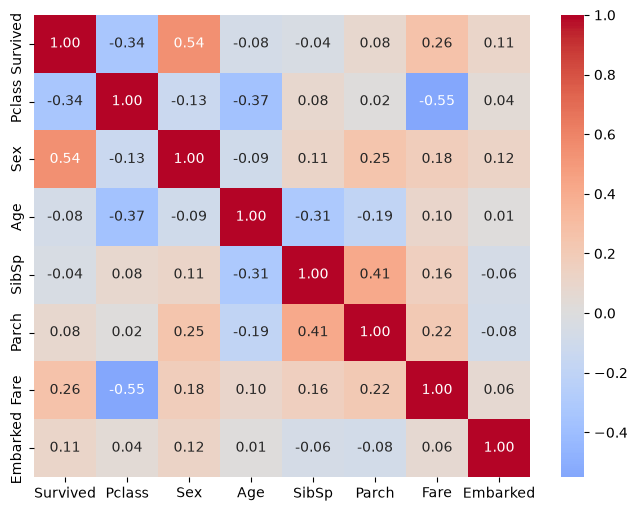

In [17]:
df_corr = df_train.copy()
df_corr['Sex'] = df_corr['Sex'].map({'male': 0, 'female': 1})
df_corr['Embarked'] = df_corr['Embarked'].map({'S': 0, 'C' : 1, 'Q': 2})
corr = df_corr.select_dtypes('number').drop(columns='PassengerId').corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

In [ ]:
df_train.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Sex,,,
female,0.742038,233,314
male,0.188908,109,577


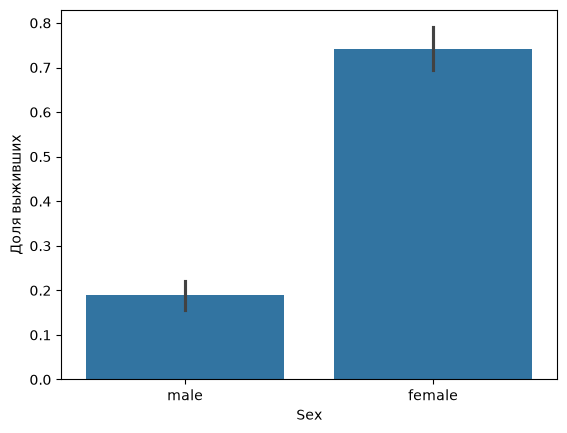

In [19]:
sns.barplot(data=df_train, x='Sex', y='Survived')
plt.ylabel('Доля выживших')
plt.show()

In [20]:
# Доля выживших по классу (и количество)
df_train.groupby('Pclass')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Pclass,,,
1,0.629630,136,216
2,0.472826,87,184
3,0.242363,119,491


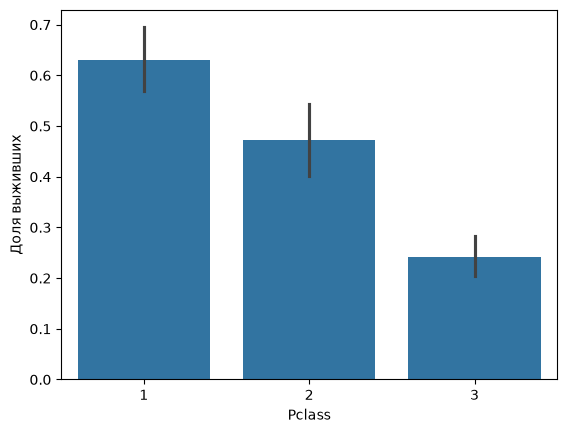

In [21]:
sns.barplot(data=df_train, x='Pclass', y='Survived')
plt.ylabel('Доля выживших')
plt.show()

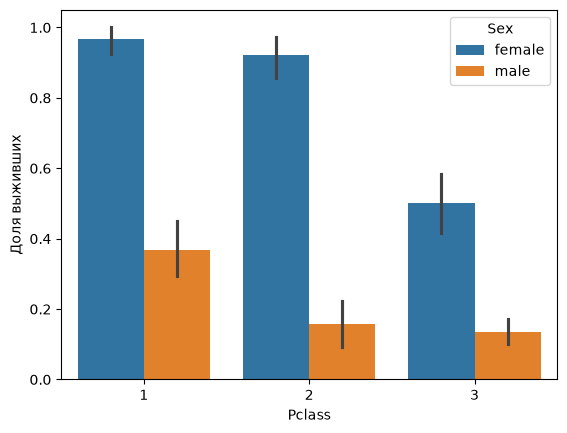

In [22]:
sns.barplot(data=df_train, x='Pclass', y='Survived', hue='Sex')
plt.ylabel('Доля выживших')
plt.show()

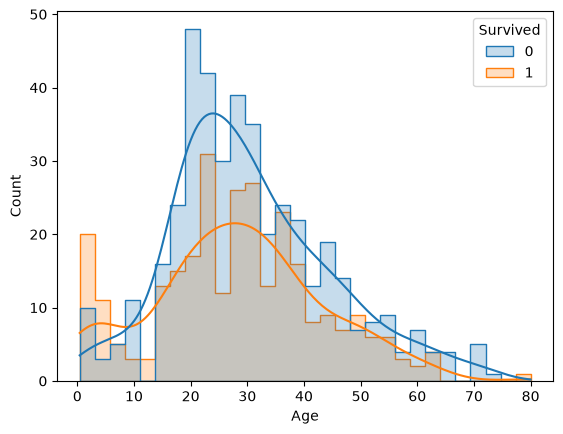

In [23]:
sns.histplot(data=df_train, x='Age', hue='Survived', bins=30, kde=True, element='step')
plt.show()

In [26]:
df_train.groupby('SibSp')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
SibSp,,,
0,0.345395,210,608
1,0.535885,112,209
2,0.464286,13,28
3,0.250000,4,16
4,0.166667,3,18
5,0.000000,0,5
8,0.000000,0,7


In [27]:
df_train.groupby('Parch')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Parch,,,
0,0.343658,233,678
1,0.550847,65,118
2,0.500000,40,80
3,0.600000,3,5
4,0.000000,0,4
5,0.200000,1,5
6,0.000000,0,1


In [28]:
df_fam = df_train.copy()
df_fam['FamilySize'] = df_fam['SibSp'] + df_fam['Parch'] + 1

df_fam.groupby('FamilySize')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
FamilySize,,,
1,0.303538,163,537
2,0.552795,89,161
3,0.578431,59,102
4,0.724138,21,29
5,0.200000,3,15
6,0.136364,3,22
7,0.333333,4,12
8,0.000000,0,6
11,0.000000,0,7


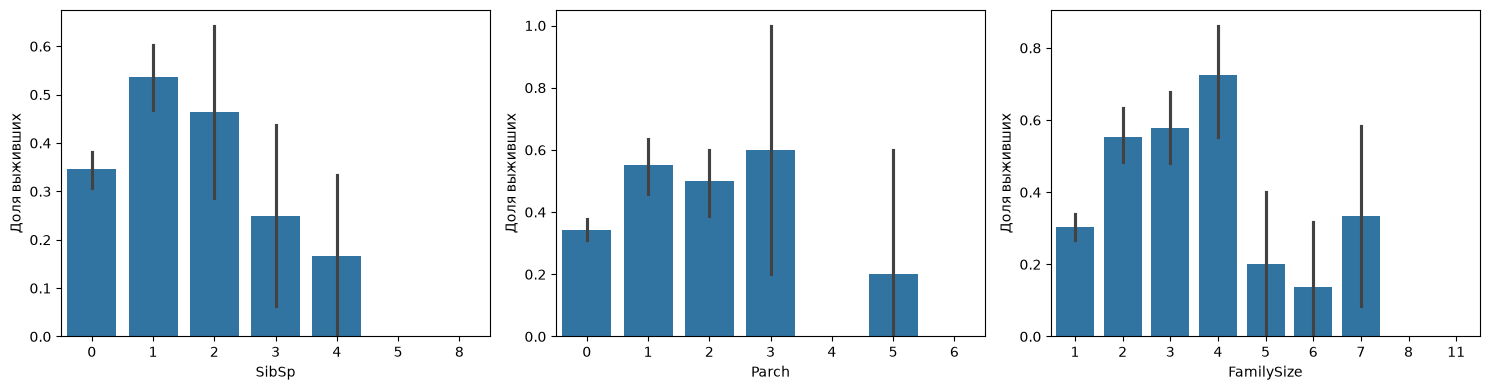

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=df_fam, x='SibSp', y='Survived', ax=axes[0])
sns.barplot(data=df_fam, x='Parch', y='Survived', ax=axes[1])
sns.barplot(data=df_fam, x='FamilySize', y='Survived', ax=axes[2])

for ax in axes:
    ax.set_ylabel('Доля выживших')

plt.tight_layout()
plt.show()

In [24]:
age_bins = [0, 5, 12, 18, 30, 45, 60, 80]
df_age = df_train.dropna(subset=['Age']).copy()
df_age['AgeGroup'] = pd.cut(df_age['Age'], bins=age_bins)

df_age.groupby('AgeGroup', observed=True)['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
AgeGroup,,,
"(0, 5]",0.704545,31,44
"(5, 12]",0.360000,9,25
"(12, 18]",0.428571,30,70
"(18, 30]",0.355556,96,270
"(30, 45]",0.425743,86,202
"(45, 60]",0.407407,33,81
"(60, 80]",0.227273,5,22


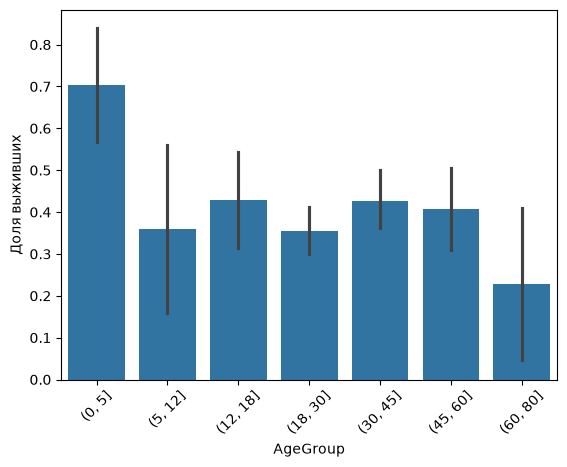

In [25]:
sns.barplot(data=df_age, x='AgeGroup', y='Survived')
plt.xticks(rotation=45)
plt.ylabel('Доля выживших')
plt.show()

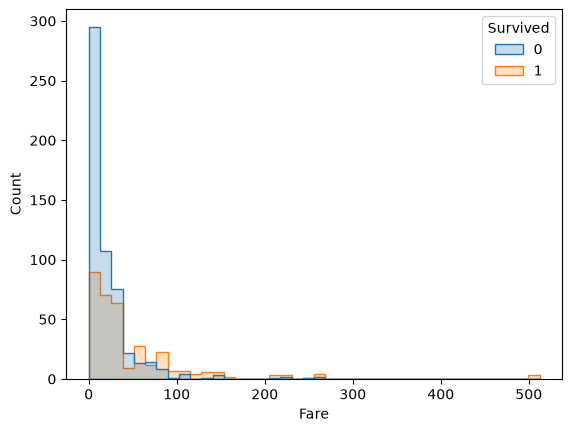

In [31]:
sns.histplot(data=df_train, x='Fare', hue='Survived', bins=40, element='step')
plt.show()

In [32]:
# Доля выживших по квантильным группам цены (в каждой примерно поровну людей)
df_fare = df_train.copy()
df_fare['FareGroup'] = pd.qcut(df_fare['Fare'], q=5, duplicates='drop')

df_fare.groupby('FareGroup', observed=True)['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
FareGroup,,,
"(-0.001, 7.854]",0.217877,39,179
"(7.854, 10.5]",0.201087,37,184
"(10.5, 21.679]",0.424419,73,172
"(21.679, 39.688]",0.444444,80,180
"(39.688, 512.329]",0.642045,113,176


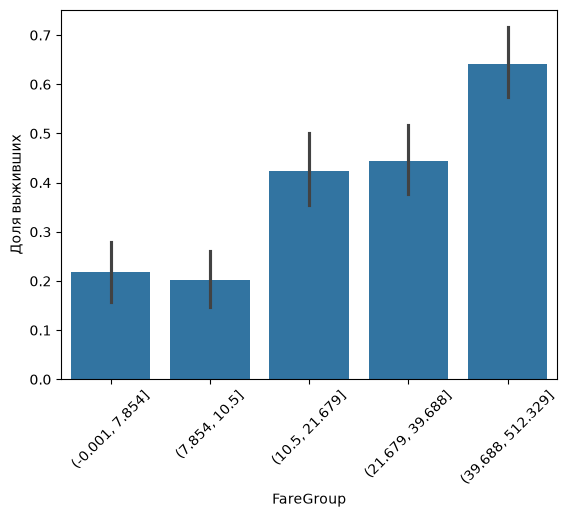

In [33]:
# График по группам
sns.barplot(data=df_fare, x='FareGroup', y='Survived')
plt.xticks(rotation=45)
plt.ylabel('Доля выживших')
plt.show()

### Предобработка и валидация

In [35]:
df_train_priz

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,0.0,1.0,0.0,0.0,1.0
1,1,1,38.0,1,0,71.2833,1.0,0.0,1.0,0.0,0.0
2,1,3,26.0,0,0,7.9250,1.0,0.0,0.0,0.0,1.0
3,1,1,35.0,1,0,53.1000,1.0,0.0,0.0,0.0,1.0
4,0,3,35.0,0,0,8.0500,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000,0.0,1.0,0.0,0.0,1.0
887,1,1,19.0,0,0,30.0000,1.0,0.0,0.0,0.0,1.0
888,0,3,28.0,1,2,23.4500,1.0,0.0,0.0,0.0,1.0
889,1,1,26.0,0,0,30.0000,0.0,1.0,1.0,0.0,0.0


In [ ]:
df_train_priz = df_train[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
df_train_priz['Age'] = df_train_priz['Age'].fillna(df_train_priz['Age'].median())
df_train_priz['Embarked'] = df_train_priz['Embarked'].fillna('S')
df_train_priz = pd.get_dummies(df_train_priz, dtype=float)

X = df_train_priz.drop('Survived', axis=1)
y = df_train_priz['Survived']

n_estimators = [x for x in range(10, 200, 10)]
best_accuracy = 0
all_accuracy = {}

for n_estimator in n_estimators:
    print("Количество деревьев: ", n_estimator)

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    array_accuracy = []
    for i, (train_index, test_index) in enumerate(skf.split(X, y)):
        current_X_train = df_train_priz.iloc[train_index].drop('Survived', axis=1)
        current_y_train = df_train_priz['Survived'].iloc[train_index]
        current_X_test  = df_train_priz.iloc[test_index].drop('Survived', axis=1)
        current_y_test  = df_train_priz['Survived'].iloc[test_index]

        model = RandomForestClassifier(n_estimators=n_estimator, max_depth=5, random_state=42)

        model.fit(current_X_train, current_y_train)

        current_accuracy = model.score(current_X_test, current_y_test, sample_weight=None)
        print(current_accuracy)
        array_accuracy.append(current_accuracy)

    mean__accuracy = float(np.mean(array_accuracy))
    print("Средняя accuracy: ", mean__accuracy, "std accuracy: ", np.std(array_accuracy))
    all_accuracy[n_estimator] = mean__accuracy
    
    if mean__accuracy > best_accuracy:
        best_accuracy = mean__accuracy
        print("Новый рекорд! ", best_accuracy)

Количество деревьев:  10
0.8324022346368715
0.8146067415730337
0.7865168539325843
0.8089887640449438
0.8426966292134831
Средняя accuracy:  0.8170422446801833 std accuracy:  0.019476480396995184
Новый рекорд!  0.8170422446801833
Количество деревьев:  20
0.8212290502793296
0.8089887640449438
0.8089887640449438
0.8202247191011236
0.848314606741573
Средняя accuracy:  0.8215491808423827 std accuracy:  0.014378962732389824
Новый рекорд!  0.8215491808423827
Количество деревьев:  30
0.8324022346368715
0.8089887640449438
0.8089887640449438
0.8202247191011236
0.848314606741573
Средняя accuracy:  0.8237838177138912 std accuracy:  0.015009937572477898
Новый рекорд!  0.8237838177138912
Количество деревьев:  40
0.8435754189944135
0.8089887640449438
0.8089887640449438
0.8202247191011236
0.8595505617977528
Средняя accuracy:  0.8282656455966354 std accuracy:  0.020104665960042064
Новый рекорд!  0.8282656455966354
Количество деревьев:  50
0.8379888268156425
0.8146067415730337
0.8089887640449438
0.820224

In [41]:
X = df_train_priz.drop('Survived', axis=1)
y = df_train_priz['Survived']

In [67]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [68]:
y_train

692    1
481    0
527    0
855    1
801    1
      ..
359    1
258    1
736    0
462    0
507    1
Name: Survived, Length: 712, dtype: int64

In [76]:
model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)

model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [64]:
predictions = model.predict(X_val)

In [77]:
model.score(X_val, y_val, sample_weight=None)

0.8156424581005587

In [ ]:
val_pred = pd.DataFrame(predictions)
result_df = pd.concat([X_val, y_val], axis=1, ignore_index=False, sort=False)
result_df = result_df.reset_index(drop=True)
pd.concat([result_df, val_pred], axis=1, ignore_index=False, sort=False).head(50)

,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Survived,0
0,3,24.00,2,0,24.1500,0.0,1.0,0.0,0.0,1.0,0,0
1,3,44.00,0,1,16.1000,0.0,1.0,0.0,0.0,1.0,0,0
2,3,22.00,0,0,7.2250,0.0,1.0,1.0,0.0,0.0,1,0
3,3,41.00,2,0,14.1083,0.0,1.0,0.0,0.0,1.0,0,0
4,3,28.00,1,0,15.5000,1.0,0.0,0.0,1.0,0.0,1,1
5,3,36.00,1,0,17.4000,1.0,0.0,0.0,0.0,1.0,1,0
6,2,36.00,0,0,13.0000,1.0,0.0,0.0,0.0,1.0,1,1
7,1,45.00,0,0,26.5500,0.0,1.0,0.0,0.0,1.0,0,0
8,1,49.00,1,1,110.8833,0.0,1.0,1.0,0.0,0.0,0,0
9,2,34.00,1,0,26.0000,0.0,1.0,0.0,0.0,1.0,0,0


In [4]:
df_train.head(50)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [29]:
df_train_priz = df_train[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
df_train_priz['Surname'] = df_train['Name'].str.split(',').str[0].str.strip()
df_train_priz['Age'] = df_train_priz['Age'].fillna(df_train_priz['Age'].median())
df_train_priz['Embarked'] = df_train_priz['Embarked'].fillna('S')
df_train_priz = pd.get_dummies(df_train_priz, dtype=float, drop_first=True)

In [30]:
df_train_priz

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Surname_Abbott,...,Surname_Yousseff,Surname_Yrois,Surname_Zabour,Surname_Zimmerman,Surname_de Messemaeker,Surname_de Mulder,Surname_de Pelsmaeker,Surname_del Carlo,Surname_van Billiard,Surname_van Melkebeke
0,0,3,22.0,1,0,7.2500,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1,38.0,1,0,71.2833,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,3,26.0,0,0,7.9250,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,1,35.0,1,0,53.1000,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,3,35.0,0,0,8.0500,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
887,1,1,19.0,0,0,30.0000,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
888,0,3,28.0,1,2,23.4500,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
889,1,1,26.0,0,0,30.0000,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [21]:
df_train['Surname'] = df_train['Name'].str.split(',').str[0].str.strip()

In [33]:
df_train['Surname'].value_counts().head(30)

Surname
Andersson        9
Sage             7
Johnson          6
Panula           6
Goodwin          6
Skoog            6
Carter           6
Rice             5
Palsson          4
Williams         4
Asplund          4
Fortune          4
Harper           4
Harris           4
Ford             4
Gustafsson       4
Smith            4
Lefebre          4
Brown            4
Kelly            4
Hart             4
Baclini          4
Moran            3
Vander Planke    3
Meyer            3
Laroche          3
West             3
Johansson        3
Jussila          3
Hickman          3
Name: count, dtype: int64

In [40]:
df_train_priz['Cabin'] = df_train['Cabin'].fillna('Z')
df_train_priz['Deck'] = df_train_priz['Cabin'].str[0]
df_train_priz = df_train_priz.drop(columns='Cabin')

In [42]:
df_train_priz

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Surname_Abbott,...,Surname_Yrois,Surname_Zabour,Surname_Zimmerman,Surname_de Messemaeker,Surname_de Mulder,Surname_de Pelsmaeker,Surname_del Carlo,Surname_van Billiard,Surname_van Melkebeke,Deck
0,0,3,22.0,1,0,7.2500,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Z
1,1,1,38.0,1,0,71.2833,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,C
2,1,3,26.0,0,0,7.9250,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Z
3,1,1,35.0,1,0,53.1000,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,C
4,0,3,35.0,0,0,8.0500,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Z
887,1,1,19.0,0,0,30.0000,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,B
888,0,3,28.0,1,2,23.4500,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Z
889,1,1,26.0,0,0,30.0000,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,C


In [38]:
df_train['Cabin'] = df_train['Cabin'].fillna('Z')

In [41]:
df_train[df_train['Pclass'] == 2].head(50)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Surname
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.00,1,0,237736,30.0708,Z,C,Nasser
15,16,1,2,"Hewlett, Mrs. (Mary D Kingcome)",female,55.00,0,0,248706,16.0000,Z,S,Hewlett
17,18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,Z,S,Williams
20,21,0,2,"Fynney, Mr. Joseph J",male,35.00,0,0,239865,26.0000,Z,S,Fynney
21,22,1,2,"Beesley, Mr. Lawrence",male,34.00,0,0,248698,13.0000,D56,S,Beesley
33,34,0,2,"Wheadon, Mr. Edward H",male,66.00,0,0,C.A. 24579,10.5000,Z,S,Wheadon
41,42,0,2,"Turpin, Mrs. William John Robert (Dorothy Ann ...",female,27.00,1,0,11668,21.0000,Z,S,Turpin
43,44,1,2,"Laroche, Miss. Simonne Marie Anne Andree",female,3.00,1,2,SC/Paris 2123,41.5792,Z,C,Laroche
53,54,1,2,"Faunthorpe, Mrs. Lizzie (Elizabeth Anne Wilkin...",female,29.00,1,0,2926,26.0000,Z,S,Faunthorpe
56,57,1,2,"Rugg, Miss. Emily",female,21.00,0,0,C.A. 31026,10.5000,Z,S,Rugg
